# Player valuation model

Predicts a player's **next-season Win Shares** (scaled to 82 games) from his last three seasons, age and availability.
The projection feeds the Valuation agent: it turns "is this player worth his contract?" into a number with an interval.

Pipeline: `models/valuation/features.py` → `train.py` (time-based split, tuning, conformal intervals) → `predict.py` (2026-27 projections, SHAP, surplus value).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from data import db
from models.valuation.features import FEATURES, TARGET, build_frame, training_rows
from models.valuation.predict import feature_label, load_artifacts

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
INK, MUTED, GRID, BLUE, ORANGE = "#1b1f24", "#7a7f86", "#e3e3dc", "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c4c4ba",
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "font.size": 10,
        "axes.titleweight": "semibold",
    }
)

con = db.connect(read_only=True)
frame = build_frame(con)
rows = training_rows(frame)
models, meta = load_artifacts()
print(f"{len(rows):,} player-seasons with a next season; {len(FEATURES)} features")

C:\Users\efesa\Desktop\Data Science Projects\nba-front-office\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


5,459 player-seasons with a next season; 53 features


## The target

Win Shares estimates how many wins a player added. Totals depend on games played, so lockout (2011-12) and COVID (2019-20, 2020-21) seasons are scaled to 82 games before anything else.
The distribution is right-skewed: most rotation players sit between 0 and 5, stars live in the tail.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


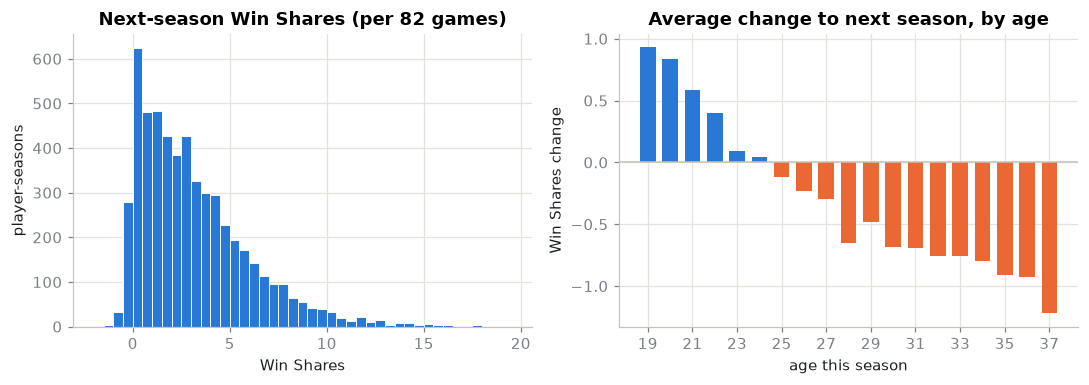

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(
    rows[TARGET], bins=np.arange(-2, 20, 0.5), color=BLUE, edgecolor="white", linewidth=0.6
)
axes[0].set(
    title="Next-season Win Shares (per 82 games)", xlabel="Win Shares", ylabel="player-seasons"
)
by_age = rows.groupby(rows["age"].clip(19, 37))[["ws_82", TARGET]].mean()
change = by_age[TARGET] - by_age["ws_82"]
axes[1].bar(
    change.index,
    change.values,
    color=[BLUE if v >= 0 else ORANGE for v in change.values],
    width=0.7,
)
axes[1].axhline(0, color="#c4c4ba", linewidth=1)
axes[1].set(
    title="Average change to next season, by age",
    xlabel="age this season",
    ylabel="Win Shares change",
)
axes[1].set_xticks(range(19, 38, 2))
fig.tight_layout()
fig.savefig(FIG / "valuation_target_and_aging.png", bbox_inches="tight")

The right panel is the aging curve the model has to learn: players improve until about 24, the average player declines from 25 on, and the drop steepens past 30. Part of the decline at every age is regression to the mean, since a season that earned more minutes is partly luck.

## Why season-normalised features
The league changed under our feet (three-point rate went from 22% to 42% of shots), so a .560 true shooting percentage meant different things in 2012 and 2025. Rate stats enter the model as z-scores within their season.

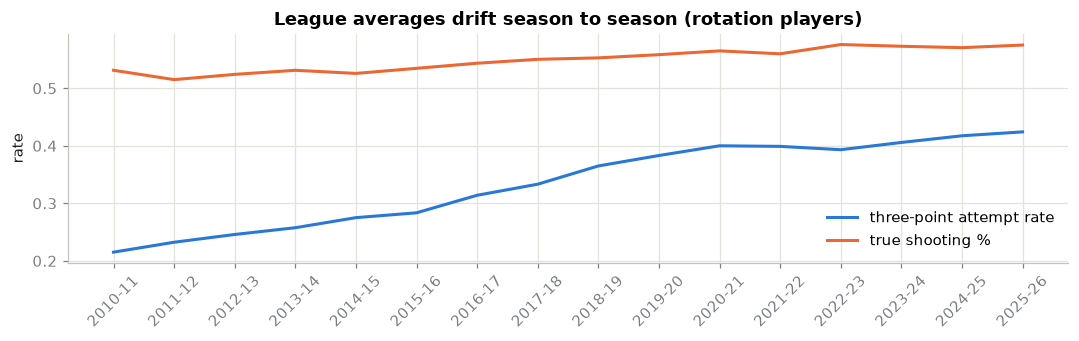

In [3]:
league = frame.groupby("season")[["ts_pct", "fg3a_rate"]].mean()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(
    league.index, league["fg3a_rate"], color=BLUE, linewidth=2, label="three-point attempt rate"
)
ax.plot(league.index, league["ts_pct"], color=ORANGE, linewidth=2, label="true shooting %")
ax.set(title="League averages drift season to season (rotation players)", ylabel="rate")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False)
fig.tight_layout()

## Results

Time-based split: hyper-parameters and the loss function were tuned with expanding-window cross-validation on seasons up to 2020-21 and checked on 2021-22 and 2022-23. **2023-24 and 2024-25 were held out as the test set** (predicting 2024-25 and 2025-26).

Baselines: persistence (next season = this season), **Marcel** (5/4/3 weighted three-year WS/48 regressed to the league mean, with an aging adjustment and projected minutes), and a ridge regression on the same features.

In [4]:
table = pd.DataFrame(
    {
        split: {m: meta[split][m]["mae"] for m in ["persistence", "marcel", "ridge", "lightgbm"]}
        for split in ["validation", "test"]
    }
)
table["test R2"] = [meta["test"][m]["r2"] for m in table.index]
table["test Spearman"] = [meta["test"][m]["spearman"] for m in table.index]
table.columns = ["validation MAE", "test MAE", "test R2", "test Spearman"]
gain = 1 - meta["test"]["lightgbm"]["mae"] / meta["test"]["marcel"]["mae"]
print(f"LightGBM test MAE is {gain:.1%} lower than Marcel; params: {meta['params']}")
table

LightGBM test MAE is 4.1% lower than Marcel; params: {'objective': 'huber', 'num_leaves': 7, 'learning_rate': 0.02, 'n_estimators': 900, 'min_child_samples': 40, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 0.0}


,validation MAE,test MAE,test R2,test Spearman
persistence,1.430,1.629,0.348,0.615
marcel,1.451,1.494,0.486,0.651
ridge,1.376,1.473,0.487,0.647
lightgbm,1.333,1.433,0.493,0.669


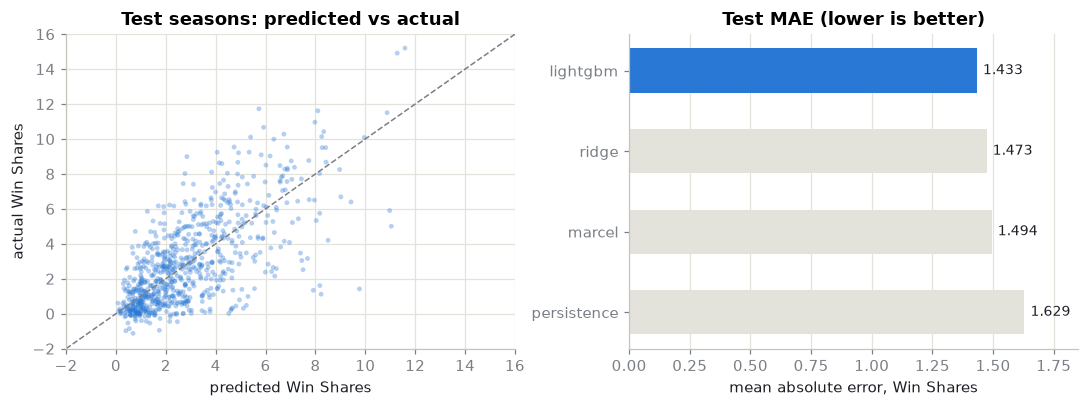

In [5]:
test = pd.read_parquet(ROOT / "models" / "artifacts" / "test_predictions.parquet")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(test["pred_lightgbm"], test[TARGET], s=10, alpha=0.35, color=BLUE, edgecolor="none")
lim = [-2, 16]
axes[0].plot(lim, lim, color=MUTED, linewidth=1, linestyle="--")
axes[0].set(
    xlim=lim,
    ylim=lim,
    title="Test seasons: predicted vs actual",
    xlabel="predicted Win Shares",
    ylabel="actual Win Shares",
)
names = ["persistence", "marcel", "ridge", "lightgbm"]
maes = [meta["test"][n]["mae"] for n in names]
bars = axes[1].barh(names, maes, color=[GRID, GRID, GRID, BLUE], height=0.55)
axes[1].bar_label(bars, labels=[f"{m:.3f}" for m in maes], padding=4, color=INK, fontsize=9)
axes[1].set(
    title="Test MAE (lower is better)", xlabel="mean absolute error, Win Shares", xlim=(0, 1.85)
)
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "valuation_results.png", bbox_inches="tight")

In [6]:
pd.DataFrame(
    {
        group: {
            k: f"{v['lightgbm_mae']:.2f} vs {v['marcel_mae']:.2f} (n={v['n']})"
            for k, v in d.items()
        }
        for group, d in meta["test_breakdown"].items()
    }
).fillna("")

,age,minutes
<=23,1.36 vs 1.42 (n=255),
24-27,1.52 vs 1.61 (n=275),
28-31,1.55 vs 1.53 (n=155),
32+,1.17 vs 1.27 (n=89),
250-1000,,1.06 vs 1.20 (n=257)
1000-2000,,1.41 vs 1.48 (n=328)
2000+,,1.97 vs 1.93 (n=189)


Errors by group on the test seasons (LightGBM vs Marcel).

## Uncertainty: conformal intervals
Quantile regression gives a 10th to 90th percentile band that should hold 80% of outcomes. The raw quantile models were too narrow, so the band is widened by a margin learned on seasons the model has not seen (conformalized quantile regression).

In [7]:
rows_cov = []
for split in ["validation", "test"]:
    iv = meta[split]["interval"]
    rows_cov.append(
        {
            "split": split,
            "raw quantiles": iv["raw_quantile_coverage"],
            "conformal": iv["conformal_coverage"],
            "target": iv["target_coverage"],
            "mean width (WS)": iv["mean_width"],
        }
    )
pd.DataFrame(rows_cov).set_index("split")

,raw quantiles,conformal,target,mean width (WS)
split,,,,
validation,0.770,0.803,0.8,4.385
test,0.714,0.767,0.8,4.281


On validation seasons the calibrated band hits the 80% target. On the test seasons it reaches about 77%: recent seasons are harder to predict than the ones the margin was learned on, which breaks the exchangeability conformal prediction assumes. The production model re-learns the margin on the most recent seasons.

## What drives a projection (SHAP)

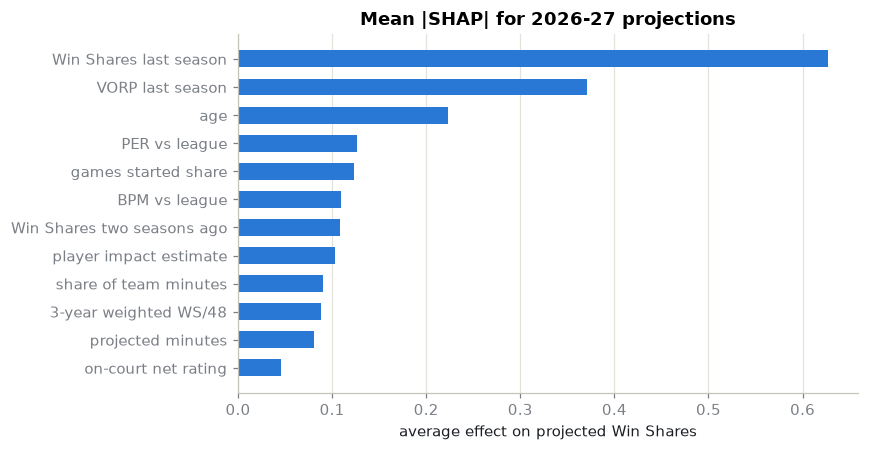

In [8]:
inputs = frame[frame["year"] == frame["year"].max()]
explainer = shap.TreeExplainer(models["point"])
values = explainer.shap_values(inputs[FEATURES])
importance = (
    pd.Series(np.abs(values).mean(axis=0), index=[feature_label(f) for f in FEATURES])
    .groupby(level=0)
    .sum()
    .sort_values()
)
top = importance.tail(12)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.set(title="Mean |SHAP| for 2026-27 projections", xlabel="average effect on projected Win Shares")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "valuation_shap.png", bbox_inches="tight")

Each projection in `player_projections` stores its own top five SHAP factors, so the Valuation agent can explain a number instead of asserting it.

## 2026-27 projections and contract value
Dollars per Win Share come from the league itself: total salary above the minimum divided by total projected Win Shares. Market value = minimum salary + dollars per Win Share x projection; surplus = market value - salary.

In [9]:
proj = con.execute("""
    SELECT p.player_name, t.abbreviation AS team, round(p.age_next) AS age, round(p.projected_ws, 1) AS ws,
           round(p.ws_p10, 1) AS p10, round(p.ws_p90, 1) AS p90, round(p.salary / 1e6, 1) AS salary_m,
           round(p.surplus_value / 1e6, 1) AS surplus_m
    FROM player_projections p LEFT JOIN teams t USING (team_id)
""").df()
proj.sort_values("ws", ascending=False).head(12)

,player_name,team,age,ws,p10,p90,salary_m,surplus_m
44,Shai Gilgeous-Alexander,OKC,28.0,11.7,5.5,15.8,40.8,11.4
42,Nikola Jokić,DEN,31.0,11.5,5.3,15.7,59.0,-7.6
101,Victor Wembanyama,SAS,23.0,9.6,4.0,14.1,16.9,26.0
82,Jalen Duren,DET,23.0,9.5,4.5,13.2,40.2,2.3
36,Luka Dončić,LAL,27.0,9.2,4.5,12.1,49.8,-8.5
65,Kawhi Leonard,TOR,35.0,8.4,3.8,9.6,50.3,-12.2
262,Giannis Antetokounmpo,MIA,32.0,8.1,3.4,12.0,58.5,-21.7
77,Chet Holmgren,OKC,24.0,7.8,3.3,11.0,41.5,-6.4
0,Amen Thompson,HOU,24.0,7.6,3.6,11.8,12.3,21.9
64,Donovan Clingan,POR,22.0,7.5,2.9,10.5,7.5,26.2


In [10]:
priced = proj.dropna(subset=["salary_m"])
pd.concat(
    {
        "best value": priced.nlargest(8, "surplus_m"),
        "most overpaid": priced.nsmallest(8, "surplus_m"),
    }
)

player_name team   age   ws  p10   p90  salary_m  \
best value    89       Neemias Queta  BOS  27.0  7.0  3.1  10.1       2.7   
              64     Donovan Clingan  POR  22.0  7.5  2.9  10.5       7.5   
              101  Victor Wembanyama  SAS  23.0  9.6  4.0  14.1      16.9   
              79        LeBron James  PHI  42.0  5.8  2.4   8.7       3.9   
              95      Moussa Diabaté  CHA  25.0  5.4  2.0   8.1       2.5   
              0        Amen Thompson  HOU  24.0  7.6  3.6  11.8      12.3   
              129        Kel'el Ware  MIL  22.0  5.7  1.7   8.6       4.7   
              15    Payton Pritchard  BOS  29.0  6.3  3.2   8.6       7.8   
most overpaid 249        Paul George  BOS  36.0  2.5  0.5   4.0      54.1   
              325      Anthony Davis  WAS  33.0  4.1  0.9   8.1      58.5   
              205      Stephen Curry  GSW  38.0  5.4  1.5   7.6      62.6   
              226        Joel Embiid  PHI  32.0  4.4  0.8   6.9      58.1   
              223        Zach LaVine  SAC  31.0  2.3  0.2   4.4      49.0   
              173  Jaren Jackson Jr.  UTA  27.0  3.2  0.4   5.8      49.0   
              336       Jayson Tatum  BOS  28.0  5.4  1.4   9.9      58.5   
              330          Ja Morant  POR  27.0  1.8  0.1   4.8      42.2   

                   surplus_m  
best value    89        29.1  
              64        26.2  
              101       26.0  
              79        22.9  
              95        22.5  
              0         21.9  
              129       21.4  
              15        21.1  
most overpaid 249      -41.9  
              325      -39.1  
              205      -37.9  
              226      -37.8  
              223      -37.6  
              173      -33.7  
              336      -33.4  
              330      -33.0

**Limitations.** Win Shares rewards rebounding and efficiency, so centres on cheap contracts rank high in surplus value. The target is conditioned on the player appearing next season: retirement and leaving the league are not modelled. Rookies without NBA minutes get no projection.

In [11]:
con.close()